# 2D sliding-window clouds with Beta innovations

Compare the points $(X_t, X_{t+1})$ for different Beta shape parameters
$(\alpha,\beta)$ while keeping the AR coefficients, sample size, and
innovation support $[a,b]$ fixed. Run all cells, then edit **Settings** and
rerun the settings and plotting cells.

Following the [thesis's Beta innovation definition](../../Abschlussarbeit_2021/LaTeX/chapters/3_application_to_time_series.tex),
the process is $X_t=\sum_{j=1}^p\phi_jX_{t-j}+Z_t$, with
$Z_t=a+(b-a)U_t$ and $U_t\sim\operatorname{Beta}(\alpha,\beta)$.
The support stays $[a,b]$ for every shape pair. The innovation mean is
$a+(b-a)\alpha/(\alpha+\beta)$ and may be nonzero; the variance also changes
with the shape parameters. With $\alpha=\beta=1$, innovations are uniform
on $[a,b]$. The default support is $[-1,1]$.

Each panel overlays the same theoretical support zonoid as a dashed red
border, since the support and AR coefficients are fixed across panels.
Every figure is also saved as PDF and PNG.

In [10]:
import sys                                                                                          ### INFRASTRUCTURE
from pathlib import Path                                                                            ### INFRASTRUCTURE

import matplotlib.pyplot as plt                                                                     ### PLOTTING
import numpy as np

AR_CODE_DIR = next(                                                                                 ### INFRASTRUCTURE
    (                                                                                               ### INFRASTRUCTURE
        candidate.resolve()                                                                         ### INFRASTRUCTURE
        for root in (Path.cwd(), *Path.cwd().parents)                                               ### INFRASTRUCTURE
        for candidate in (root / "Code" / "Code_AR_processes", root)                                ### INFRASTRUCTURE
        if (candidate / "ar_tools/functions.py").is_file()                                          ### INFRASTRUCTURE
        and (candidate / "ar_tools/plotting_functions.py").is_file()                                ### INFRASTRUCTURE
    ),                                                                                              ### INFRASTRUCTURE
    None,                                                                                           ### INFRASTRUCTURE
)                                                                                                   ### INFRASTRUCTURE
if AR_CODE_DIR is None:                                                                             ### INFRASTRUCTURE
    raise FileNotFoundError("Run this notebook from the project or AR code folder.")                ### INFRASTRUCTURE

PROJECT_ROOT = AR_CODE_DIR.parents[1]                                                               ### INFRASTRUCTURE
if str(PROJECT_ROOT) not in sys.path:                                                               ### INFRASTRUCTURE
    sys.path.insert(0, str(PROJECT_ROOT))                                                           ### INFRASTRUCTURE

from Code.Code_AR_processes.ar_tools.functions import (
    is_stationary,
    simulate_beta_ar,
    sliding_window_point_cloud,
)

NOTEBOOK_NAME = "ar_beta_sliding_window_2d"                                                         ### INFRASTRUCTURE
PDF_DIR = AR_CODE_DIR / "outputs" / "pdfs" / NOTEBOOK_NAME                                          ### INFRASTRUCTURE
IMAGE_DIR = AR_CODE_DIR / "outputs" / "images" / NOTEBOOK_NAME                                      ### INFRASTRUCTURE
PDF_DIR.mkdir(parents=True, exist_ok=True)                                                          ### INFRASTRUCTURE
IMAGE_DIR.mkdir(parents=True, exist_ok=True)                                                        ### INFRASTRUCTURE

## Settings

Edit `beta_pairs` to choose the panels. For one cloud, use e.g.
`beta_pairs = [(2.0, 5.0)]`. Both shape parameters must be positive.
Set `innovation_bounds = (a, b)` to choose the fixed support interval.
`phi = np.array([0.7])` gives an AR(1) process; use a longer stationary
coefficient vector for AR(2), AR(3), etc.

The seed is reset for each pair to make reruns reproducible. All panels
use identical axis limits and equal axis scales, with every point and the
whole zonoid shown. The border comes from the innovation support and AR
coefficients. AR(1) uses the exact infinite-history boundary; higher orders
use a finite-history approximation controlled by `zonoid_history` (increase
it for coefficients close to the stationarity boundary).

In [11]:
phi = np.array([0.7])
beta_pairs = [
    (1.0, 1.0),
    (0.5, 0.5),
    (2.0, 2.0),
    (5.0, 5.0),
    (2.0, 5.0),
    (5.0, 2.0),
]

sample_size = 5_000
burnin = 1_000
innovation_bounds = (-1.0, 1.0)
process_seed = 42
columns = 3
point_size = 4
point_alpha = 0.35

# Only used for AR orders greater than one.
zonoid_history = 2_000


In [12]:
from Code.Code_AR_processes.ar_tools.support_geometry import theoretical_support_zonoid_2d


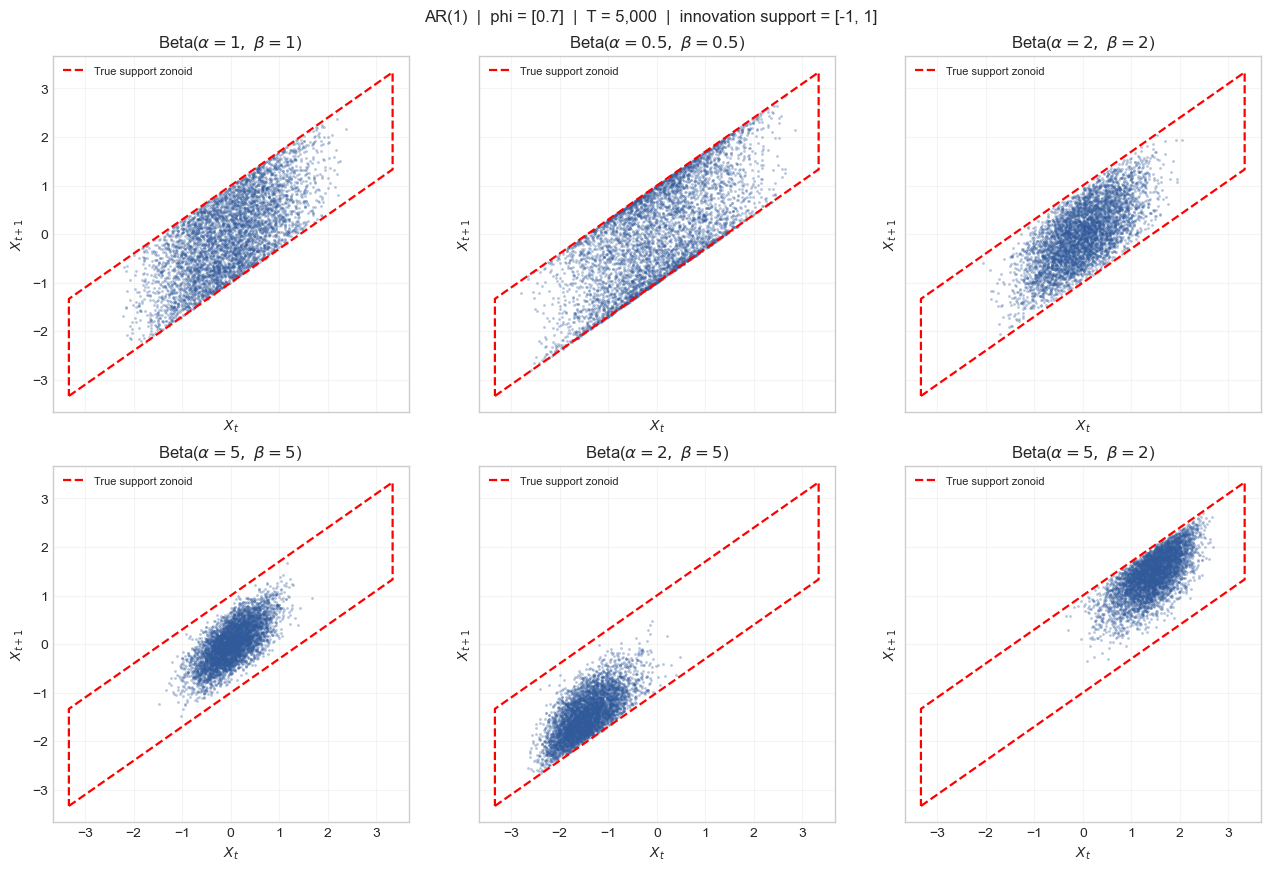

PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/outputs/pdfs/ar_beta_sliding_window_2d/beta_sliding_window_clouds_2d.pdf
PNG: /Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/outputs/images/ar_beta_sliding_window_2d/beta_sliding_window_clouds_2d.png


In [13]:
import importlib
from Code.Code_AR_processes.ar_tools import functions as ar_functions

# Refresh the simulator after shared-code edits in an existing notebook session.
simulate_beta_ar = importlib.reload(ar_functions).simulate_beta_ar

phi = np.asarray(phi, dtype=float)
if phi.ndim != 1 or len(phi) == 0 or not np.all(np.isfinite(phi)):
    raise ValueError("phi must be a nonempty, finite coefficient vector.")
stationary, _ = is_stationary(phi)
if not stationary:
    raise ValueError("Choose stationary AR coefficients (companion eigenvalues inside the unit circle).")
if not isinstance(sample_size, (int, np.integer)) or sample_size < 2:
    raise ValueError("sample_size must be an integer of at least 2.")
if not beta_pairs:
    raise ValueError("Add at least one (alpha, beta) pair to beta_pairs.")
if not isinstance(columns, (int, np.integer)) or columns < 1:
    raise ValueError("columns must be a positive integer.")

clouds = []
zonoid_boundaries = []
for alpha, beta in beta_pairs:
    zonoid_boundaries.append(theoretical_support_zonoid_2d(
        phi, innovation_bounds, history=zonoid_history
    ))
    series = simulate_beta_ar(
        phi,
        sample_size=sample_size,
        burnin=burnin,
        innovation_bounds=innovation_bounds,
        alpha=alpha,
        beta=beta,
        rng=process_seed,
    )
    cloud = sliding_window_point_cloud(
        series, embedding_dimension=2, newest_first=False
    )
    if not np.all(np.isfinite(cloud)):
        raise ValueError("The simulated cloud contains nonfinite values.")
    clouds.append(cloud)

all_shapes = clouds + zonoid_boundaries                                                             ### PLOTTING
lower = min(float(points.min()) for points in all_shapes)                                           ### PLOTTING
upper = max(float(points.max()) for points in all_shapes)                                           ### PLOTTING
margin = 0.05 * max(upper - lower, np.finfo(float).eps)                                             ### PLOTTING
axis_limits = (lower - margin, upper + margin)                                                      ### PLOTTING
ncols = min(columns, len(beta_pairs))                                                               ### PLOTTING
nrows = (len(beta_pairs) + ncols - 1) // ncols                                                      ### PLOTTING

with plt.style.context("seaborn-v0_8-whitegrid"):                                                   ### PLOTTING
    fig, axes = plt.subplots(                                                                       ### PLOTTING
        nrows, ncols,                                                                               ### PLOTTING
        figsize=(4.3 * ncols, 4.3 * nrows),                                                         ### PLOTTING
        sharex=True, sharey=True, squeeze=False,                                                    ### PLOTTING
        constrained_layout=True,                                                                    ### PLOTTING
    )                                                                                               ### PLOTTING
    for ax, (alpha, beta), cloud, boundary in zip(                                                ### PLOTTING
        axes.flat, beta_pairs, clouds, zonoid_boundaries                                            ### PLOTTING
    ):                                                                                              ### PLOTTING
        ax.scatter(                                                                                 ### PLOTTING
            cloud[:, 0], cloud[:, 1],                                                               ### PLOTTING
            s=point_size, alpha=point_alpha,                                                        ### PLOTTING
            color="#315a9a", linewidths=0, rasterized=True,                                         ### PLOTTING
        )                                                                                           ### PLOTTING
        ax.plot(                                                                                    ### PLOTTING
            boundary[:, 0], boundary[:, 1],                                                         ### PLOTTING
            color="red", linestyle="--", linewidth=1.6, zorder=3,                                   ### PLOTTING
            label="True support zonoid" if len(phi) == 1                                            ### PLOTTING
            else f"Support zonoid (H={zonoid_history:,})",                                          ### PLOTTING
        )                                                                                           ### PLOTTING
        ax.legend(loc="upper left", fontsize=8, framealpha=0.9)                                     ### PLOTTING
        ax.set(                                                                                     ### PLOTTING
            title=fr"Beta($\alpha={alpha:g},\ \beta={beta:g}$)",                                  ### PLOTTING
            xlabel=r"$X_t$", ylabel=r"$X_{t+1}$",                                                   ### PLOTTING
            xlim=axis_limits, ylim=axis_limits,                                                     ### PLOTTING
        )                                                                                           ### PLOTTING
        ax.set_aspect("equal", adjustable="box")                                                    ### PLOTTING
        ax.grid(alpha=0.2)                                                                          ### PLOTTING
    for ax in list(axes.flat)[len(beta_pairs):]:                                                    ### PLOTTING
        ax.set_visible(False)                                                                       ### PLOTTING

    coefficient_label = np.array2string(phi, precision=3, separator=", ")                           ### PLOTTING
    fig.suptitle(                                                                                   ### PLOTTING
        f"AR({len(phi)})  |  phi = {coefficient_label}  |  "                                        ### PLOTTING
        f"T = {sample_size:,}  |  innovation support = "                                          ### PLOTTING
        f"[{innovation_bounds[0]:g}, {innovation_bounds[1]:g}]",                                  ### PLOTTING
        fontsize=12,                                                                                ### PLOTTING
    )                                                                                               ### PLOTTING
    pdf_path = PDF_DIR / "beta_sliding_window_clouds_2d.pdf"                                        ### PLOTTING
    image_path = IMAGE_DIR / "beta_sliding_window_clouds_2d.png"                                    ### PLOTTING
    fig.savefig(pdf_path, bbox_inches="tight")                                                      ### PLOTTING
    fig.savefig(image_path, dpi=180, bbox_inches="tight")                                           ### PLOTTING
    plt.show()                                                                                      ### PLOTTING
    plt.close(fig)                                                                                  ### PLOTTING

print(f"PDF: {pdf_path}")                                                                           ### REPORTING
print(f"PNG: {image_path}")                                                                         ### REPORTING